# Antenna Tilt — 1b: one sector + demand, and what "best tilt" means

Stage 1a gave a single sector's spatial radio model. 1b puts **users** on it: a demand field
$\rho(x,y)$ over a chosen service region, and the $\rho$-weighted metrics that turn the field into
numbers to optimize. New logic lives in `telecomopt.coverage`.

The point of 1b is conceptual: a location's **radio quality** (its SE) and its **importance** ($\rho$)
are *separate* inputs. Changing demand does not change the SNR map — it changes how we *judge* that map.

**Setup, stated explicitly.** Single sector ⇒ no interferers ⇒ SINR = SNR. Electrical tilt only
(mechanical tilt $=0$). **All** RF constants — geometry, pattern, **and** power/noise — are [E] Table I
via `RFParams`, passed into every call; none are our own invented values. The *modelling choices* that
are ours are the evaluation region, the service threshold, and the tilt range. The service region is a
**chosen** evaluation window — the sector's $\pm 60°$ wedge from $d_{\min}=35$ m (D09) to $d_{\max}=250$
m. ($250$ m = half-ISD, a stand-in: it is not the true sector boundary in every direction — best-server
fixes that in Stage 2, OQ4.) Every number below is specific to *this* region, these $\rho$'s, and this
model — not a universal optimal angle.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from telecomopt.rf import RFParams
from telecomopt.coverage import *

In [2]:
p = RFParams()   # [E] Table I constants, passed into every coverage call below
dist, az, area = sample_wedge(d_min=35.0, d_max=250.0, half_az_deg=60.0, n_r=60, n_az=61)
x, y = to_xy(dist, az)
print(f"{dist.size} sample points over the +/-60 deg wedge, 35-250 m; "
      f"total area {area.sum()/1e3:.1f} x10^3 m^2 (analytic wedge area is a consistency check)")
print(f"P = {p.p_dbm} dBm/PRB, N0 = {p.n0_dbm} dBm/PRB, G0 = {p.g0_dbi} dBi, mechanical tilt = 0 deg")

3660 sample points over the +/-60 deg wedge, 35-250 m; total area 64.2 x10^3 m^2 (analytic wedge area is a consistency check)
P = 29.0 dBm/PRB, N0 = -111.0 dBm/PRB, G0 = 18.0 dBi, mechanical tilt = 0 deg


## 1. The demand field $\rho(x,y)$

$\rho$ says *whose experience* we optimize. **Uniform** $\rho=1$ gives area-based metrics (every patch
of ground counts equally). **User density** concentrates weight where people are — here a Gaussian
hotspot on a small background floor.

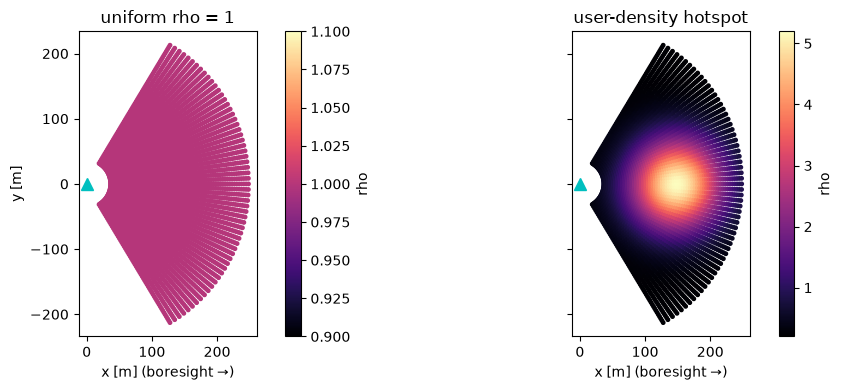

In [3]:
dem_uniform = uniform_demand(dist, az)
dem_hotspot = hotspot_demand(x, y, centers=[(150.0, 0.0)], sigmas=[50.0], peaks=[5.0], floor=0.2)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
for axn, (title, dem) in zip(axes, [("uniform rho = 1", dem_uniform), ("user-density hotspot", dem_hotspot)]):
    sc = axn.scatter(x, y, c=dem, s=6, cmap="magma")
    axn.plot(0, 0, "c^", ms=9); axn.set_aspect("equal")
    axn.set_title(title); axn.set_xlabel("x [m] (boresight →)")
    fig.colorbar(sc, ax=axn, label="rho")
axes[0].set_ylabel("y [m]")
plt.tight_layout(); plt.show()

## 2. The metrics, defined explicitly

Each sample $i$ has a spectral efficiency $C_i(t)$ (at tilt $t$), a demand $\rho_i$, and an area element
$\Delta A_i$. The aggregation weight and its normalized form are

$$w_i = \rho_i\,\Delta A_i, \qquad p_i = \frac{w_i}{\sum_j w_j}, \qquad \textstyle\sum_j w_j > 0.$$

The three metrics are then

$$\bar C(t)=\sum_i p_i\,C_i(t)\ \text{(mean SE)},\qquad
f_{\text{served}}(t;\gamma)=\sum_i p_i\,\mathbf 1\{C_i(t)\ge\gamma\}\ \text{(served fraction)},$$
$$F_t(c)=\sum_i p_i\,\mathbf 1\{C_i(t)\le c\},\qquad
C_{0.05}(t)=\inf\{c:F_t(c)\ge 0.05\}\ \text{(5th-percentile SE)}.$$

Two properties follow directly. (i) **Scale invariance:** multiplying every $\rho_i$ by the same
positive constant leaves all three unchanged — this model captures *where* demand is, not the effect of
*total load*. (ii) On a polar grid $\Delta A_i = r\,\Delta r\,\Delta\varphi$, so equally-spaced samples
are **not** equal-area; the area weighting is essential (hence `sample_wedge` returns `area`).

$C_{0.05}$ is a **threshold** — a boundary value, *not* the mean of the worst 5%; improving one very poor
location need not move it until that location reaches the cutoff. The implementation uses the
**inverse-empirical-CDF** (lower) convention (smallest value whose cumulative weight reaches 5%, no
interpolation), so a different convention can give a slightly different discrete value.

In [4]:
rep = coverage_report(8.0, dist, az, dem_uniform, area, threshold=1.0, params=p)
print("uniform demand, tilt 8 deg:")
for k, v in rep.items():
    print(f"  {k:16s} = {v:.3f}")

uniform demand, tilt 8 deg:
  mean_se          = 14.782
  p5_se            = 12.441
  served_fraction  = 1.000


**On the service threshold and served fraction.** The bar $\gamma = 1$ bps/Hz below is
**illustrative**, not a justified service requirement. With this region, bar, power and noise, SE is
10.6–19 bps/Hz across the wedge *at tilt 8°*; its minimum over **all** locations and **all** swept tilts
(2–18°) is **6.1 bps/Hz** — still far above $\gamma=1$, so served fraction is $100\%$ across the whole
sweep and cannot rank tilts *in this scenario*. That is a property of the scenario, not a law: a single
sector can still have holes from distance, weak off-axis gain, shadowing, or a stricter bar. Served
fraction may become discriminating once interference enters (Stage 2). In 1b, the **mean** and the
**5th-percentile** do the work.

## 3. Optimize under each objective

Sweep the electrical tilt over **2–18°** (a *model-exploration* range, not a specific antenna's RET
limits) and read each metric. Mean SE (a **capacity proxy** — true capacity also needs bandwidth,
scheduling and load, none modelled here) and the 5th-percentile peak at *different* tilts. This
preference is **emergent** from geometry + pattern + propagation + weights — the mean does not "favour
near-tower users"; it counts weighted improvements wherever they occur. (Why the mean prefers a steeper
beam: it lifts SE across the populous mid-region more than it costs the thin far edge, and the mean —
unlike the 5th-percentile — rewards that bulk gain.)

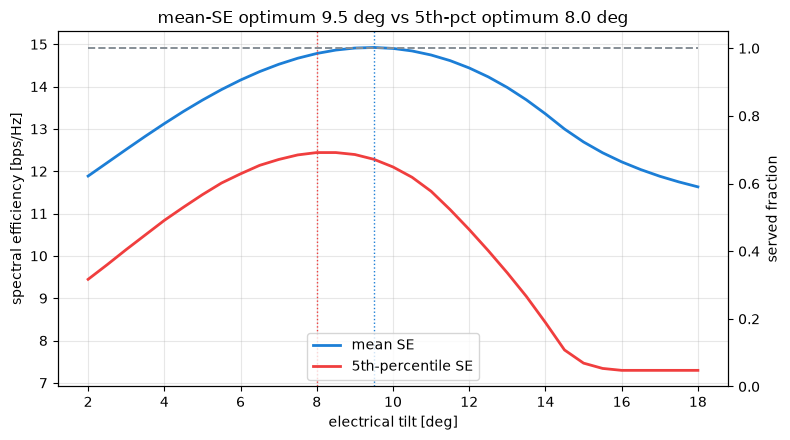

In [5]:
tilts = np.arange(2.0, 18.1, 0.5)
reps = [coverage_report(t, dist, az, dem_uniform, area, threshold=1.0, params=p) for t in tilts]
mean_se = np.array([r["mean_se"] for r in reps])
p5 = np.array([r["p5_se"] for r in reps])
sf = np.array([r["served_fraction"] for r in reps])
i_mean, i_p5 = int(mean_se.argmax()), int(p5.argmax())

fig, axL = plt.subplots(figsize=(8, 4.5))
axL.plot(tilts, mean_se, color="#1c7ed6", lw=2, label="mean SE")
axL.plot(tilts, p5, color="#f03e3e", lw=2, label="5th-percentile SE")
axL.axvline(tilts[i_mean], color="#1c7ed6", ls=":", lw=1)
axL.axvline(tilts[i_p5], color="#f03e3e", ls=":", lw=1)
axL.set_xlabel("electrical tilt [deg]"); axL.set_ylabel("spectral efficiency [bps/Hz]")
axR = axL.twinx()
axR.plot(tilts, sf, color="#868e96", lw=1.4, ls="--", label="served frac (SE>=1, illustrative)")
axR.set_ylabel("served fraction"); axR.set_ylim(0, 1.05)
axL.legend(loc="lower center"); axL.grid(alpha=0.3)
axL.set_title(f"mean-SE optimum {tilts[i_mean]:.1f} deg vs 5th-pct optimum {tilts[i_p5]:.1f} deg")
plt.tight_layout(); plt.show()

## 4. Objective space, the Pareto front, and the *size* of the trade-off

Different argmax tilts do not by themselves mean a costly trade-off. Plotting the two objectives against
each other, a tilt $t_a$ **dominates** $t_b$ when it is **no worse on either** objective and **strictly
better on at least one** ($\bar C(t_a)\ge\bar C(t_b)$ and $C_{0.05}(t_a)\ge C_{0.05}(t_b)$, at least one
strict). The **Pareto front** is only the *non-dominated* tilts — the genuine trade-off; every other
tilt is dominated and should be discarded first. Then we ask what the trade-off actually costs.

non-dominated tilts (the Pareto front): [8.0, 8.5, 9.0, 9.5]
choosing the 5th-pct optimum (8.0 deg) costs 0.142 bps/Hz of mean (0.9%)
choosing the mean optimum (9.5 deg) costs 0.160 bps/Hz of 5th-pct (1.3%)


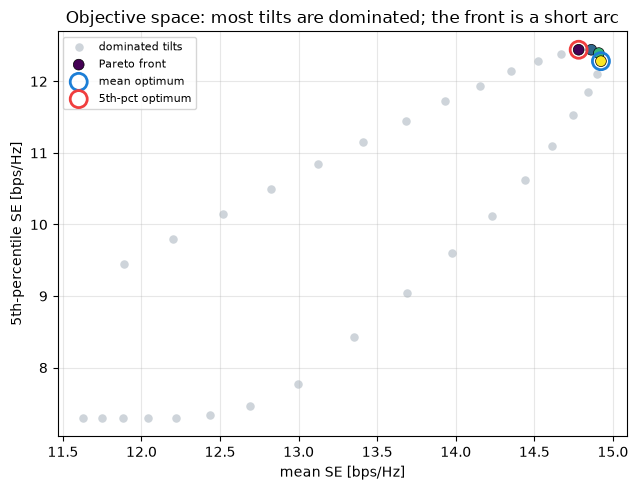

In [6]:
def non_dominated(a, b):
    nd = np.ones(len(a), bool)
    for i in range(len(a)):
        dominated = (a >= a[i]) & (b >= b[i]) & ((a > a[i]) | (b > b[i]))
        nd[i] = not dominated.any()
    return nd

nd = non_dominated(mean_se, p5)
# cost of committing to one optimum, measured on the other objective:
mean_loss = mean_se[i_mean] - mean_se[i_p5]     # mean-SE given up by choosing the 5th-pct optimum
p5_loss   = p5[i_p5]   - p5[i_mean]             # 5th-pct given up by choosing the mean optimum
print(f"non-dominated tilts (the Pareto front): {sorted(tilts[nd])}")
print(f"choosing the 5th-pct optimum ({tilts[i_p5]:.1f} deg) costs {mean_loss:.3f} bps/Hz of mean "
      f"({100*mean_loss/mean_se[i_mean]:.1f}%)")
print(f"choosing the mean optimum ({tilts[i_mean]:.1f} deg) costs {p5_loss:.3f} bps/Hz of 5th-pct "
      f"({100*p5_loss/p5[i_p5]:.1f}%)")

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(mean_se[~nd], p5[~nd], c="#ced4da", s=26, label="dominated tilts")
ax.scatter(mean_se[nd], p5[nd], c=tilts[nd], cmap="viridis", s=60, ec="k", lw=0.5, label="Pareto front")
ax.scatter(mean_se[i_mean], p5[i_mean], s=150, facecolors="none", edgecolors="#1c7ed6", lw=2, label="mean optimum")
ax.scatter(mean_se[i_p5], p5[i_p5], s=150, facecolors="none", edgecolors="#f03e3e", lw=2, label="5th-pct optimum")
ax.set_xlabel("mean SE [bps/Hz]"); ax.set_ylabel("5th-percentile SE [bps/Hz]")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
ax.set_title("Objective space: most tilts are dominated; the front is a short arc")
plt.tight_layout(); plt.show()

The trade-off is a **broad plateau**: committing to either optimum costs the other barely ~1%. So
"the objectives disagree" is true in *argmax* but almost free in practice here — any tilt on the short
8–9.5° front is near-optimal for both. That is the useful optimization reading, not the bare fact that
the argmaxes differ.

## 5. What the 5th-percentile actually selects (not "the edge")

The 5th-percentile is the lower tail of the *demand-weighted* distribution — "cell-edge" is only
conventional shorthand. The points in that tail need not be the outermost ring; let us see where they
are.

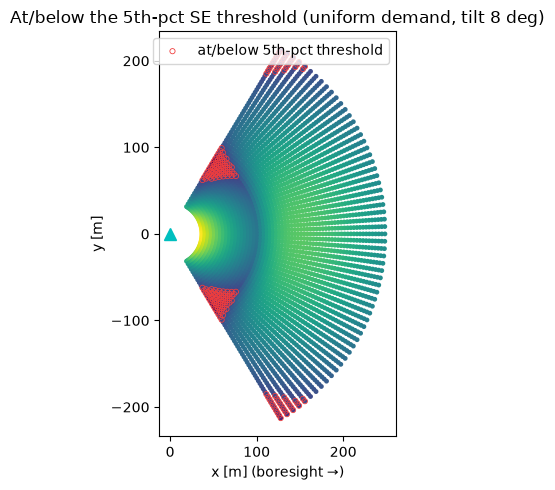

selected (C_i <= C_0.05) carries 5.0% of weight (ties can exceed 5%)
they span distance 73-248 m, |azimuth| up to 59 deg


In [7]:
se8 = spectral_efficiency_field(8.0, dist, az, params=p)
w = dem_uniform * area
thr5 = weighted_percentile(se8, w, 5.0)
low = se8 <= thr5

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(x, y, c=se8, s=6, cmap="viridis")
ax.scatter(x[low], y[low], s=14, facecolors="none", edgecolors="#f03e3e", lw=0.6,
           label="at/below 5th-pct threshold")
ax.plot(0, 0, "c^", ms=9); ax.set_aspect("equal")
ax.set_xlabel("x [m] (boresight →)"); ax.set_ylabel("y [m]")
ax.legend(loc="upper right"); ax.set_title("At/below the 5th-pct SE threshold (uniform demand, tilt 8 deg)")
plt.tight_layout(); plt.show()

print(f"selected (C_i <= C_0.05) carries {100*w[low].sum()/w.sum():.1f}% of weight (ties can exceed 5%)")
print(f"they span distance {dist[low].min():.0f}-{dist[low].max():.0f} m, "
      f"|azimuth| up to {np.abs(az[low]).max():.0f} deg")

The worst 5% are **not** a thin outer ring: they run from ~70 m to the far edge and reach the
azimuth boundary (|az| ≈ 60°). The tail is dominated by **large-azimuth** points, where the azimuth
pattern falls off — so optimizing the 5th-percentile is protecting off-boresight users as much as far
ones. (This is also *our* 5th-percentile-of-SE definition, a deliberate choice — distinct from [E]'s
5th-percentile-of-path-gain coverage.)

## 6. The optimum moves with demand — with the background floor accounted for

With the model fixed we can ask how the best tilt depends on *where* users are. Both hotspots are
truncated by the wedge, the near one also by the inner exclusion, and the background floor spreads demand
over a large area — so its *weight share* (not its height) is what matters for a tail metric.

near-demand: background floor is 14% of total weight
edge-demand: background floor is 16% of total weight


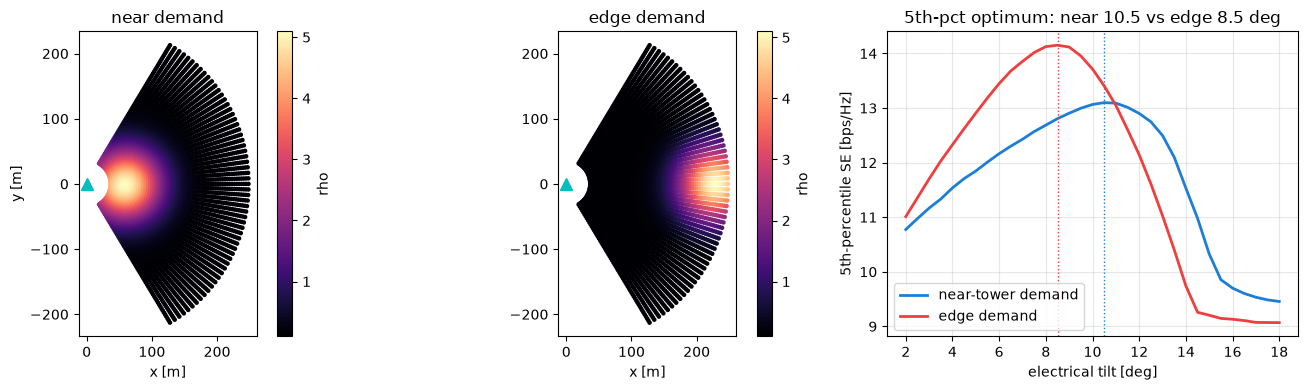

In [8]:
near = hotspot_demand(x, y, centers=[(60.0, 0.0)], sigmas=[40.0], peaks=[5.0], floor=0.1)
edge = hotspot_demand(x, y, centers=[(230.0, 0.0)], sigmas=[40.0], peaks=[5.0], floor=0.1)
for lbl, rho in [("near", near), ("edge", edge)]:
    frac = (0.1 * area).sum() / (rho * area).sum()
    print(f"{lbl}-demand: background floor is {100*frac:.0f}% of total weight")

p5_near = np.array([coverage_report(t, dist, az, near, area, params=p)["p5_se"] for t in tilts])
p5_edge = np.array([coverage_report(t, dist, az, edge, area, params=p)["p5_se"] for t in tilts])

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for axn, (lbl, rho) in zip(axes[:2], [("near demand", near), ("edge demand", edge)]):
    sc = axn.scatter(x, y, c=rho, s=5, cmap="magma")
    axn.plot(0, 0, "c^", ms=8); axn.set_aspect("equal")
    axn.set_title(lbl); axn.set_xlabel("x [m]")
    fig.colorbar(sc, ax=axn, label="rho")
axes[0].set_ylabel("y [m]")
for lbl, curve, col in [("near-tower demand", p5_near, "#1c7ed6"), ("edge demand", p5_edge, "#f03e3e")]:
    axes[2].plot(tilts, curve, lw=2, color=col, label=lbl)
    axes[2].axvline(tilts[int(curve.argmax())], color=col, ls=":", lw=1)
axes[2].set_xlabel("electrical tilt [deg]"); axes[2].set_ylabel("5th-percentile SE [bps/Hz]")
axes[2].legend(); axes[2].grid(alpha=0.3)
axes[2].set_title(f"5th-pct optimum: near {tilts[int(p5_near.argmax())]:.1f} vs edge {tilts[int(p5_edge.argmax())]:.1f} deg")
plt.tight_layout(); plt.show()

The optimum shifts with demand (near steeper, edge shallower), but note it protects the whole
weighted tail — including that ~15% background — so it need not aim straight at the hotspot centre. This
is the demand-driven CCO idea (OQ9) on our own model, for *these* distributions.

In [9]:
# Resolution check: refine the spatial grid (tilt step fixed) and the tilt step (grid fixed) separately.
def _opt(n_r, n_az, step):
    d, a, ar = sample_wedge(35.0, 250.0, 60.0, n_r, n_az); dem = uniform_demand(d, a)
    ts = np.arange(2.0, 18.0001, step)
    reps = [coverage_report(t, d, a, dem, ar, params=p) for t in ts]
    ms = np.array([r["mean_se"] for r in reps]); q5 = np.array([r["p5_se"] for r in reps])
    return ts[ms.argmax()], ms.max(), ts[q5.argmax()], q5.max()

print(f"{'case':36s}{'mean-opt':>9}{'mean':>7}{'p5-opt':>8}{'p5':>7}")
for name, cfg in [("grid 60x61,  tilt 0.50 (base) ", (60, 61, 0.50)),
                  ("grid 120x121, tilt 0.50 (finer grid)", (120, 121, 0.50)),
                  ("grid 60x61,  tilt 0.25 (finer tilt)", (60, 61, 0.25))]:
    tm, mv, tq, qv = _opt(*cfg)
    print(f"{name:36s}{tm:>9.2f}{mv:>7.2f}{tq:>8.2f}{qv:>7.2f}")

case                                 mean-opt   mean  p5-opt     p5
grid 60x61,  tilt 0.50 (base)            9.50  14.92    8.00  12.44
grid 120x121, tilt 0.50 (finer grid)     9.50  14.92    8.50  12.44
grid 60x61,  tilt 0.25 (finer tilt)      9.50  14.92    8.25  12.46


## 7. Stability and scope

The table above isolates the two resolutions. The **mean-SE optimum is stable at 9.5°**; the
**5th-percentile optimum sits at 8.0–8.5°**, shifting by ~0.5° as the spatial grid or tilt step is
refined — so the honest statement is *stable under this refinement*, not accurate to 0.25°. That
sensitivity only reinforces the main point: **the exact angle matters less than the choice of objective
and demand.** This is a *numerical* check; **shadow fading and the uncertainty analysis (D06) are a
separate, still-pending modelling layer** — these are deterministic, median-link results.

**Stage 1b, honestly.** One sector now has a demand field, three explicitly-defined $\rho$-weighted
metrics, a Pareto view in which only a short 8–9.5° arc survives, and a trade-off whose *cost* is ~1% —
a plateau, not a sharp conflict. The 5th-percentile tail is off-boresight as much as far out, and the
optimum tracks demand (background weight included).

**Stage 2** adds a second sector: best-server assignment, real **interference** (SINR, not SNR) in the
overlap — where served fraction may finally discriminate — and the first *coupled* tilt trade-off. The
**moving-frame** decomposition (OQ1) and the QUBO/QAOA solve follow as the network grows.